# Native Sparse Attention, part 6: native trainability
*Companion notebooks to Yuan et al., 2025, [Native Sparse Attention](https://arxiv.org/abs/2502.11089). Part 6 of 7: the last piece, and the one the paper's title leans on ("natively trainable").*

**TL;DR.** Most earlier sparse-attention methods take a model trained with full attention and make it sparse *afterwards*. Yuan et al. argue this has two costs: the trained model's attention was never sparse, so cutting it hurts, and nothing about sparsity helps *training*. NSA is trained sparse from the first step. In their 3B-parameter comparison (section 6.1, Figure 7) NSA reached lower training loss than two alternative ways of choosing blocks: one with an auxiliary loss, one with a parameter-free heuristic. We test the same question on our toy, with **our** numbers: train full attention and sparsify it after the fact with cheap selectors, against NSA trained sparse, against NSA variants that use the heuristic or random block choice. We report what came out, including where the toy cannot reproduce the paper's picture.

<img src="nsa_assets/fig7_alternatives.png" width="430"/>

*Figure 7 of the paper: training loss on a 3B model for full attention, an auxiliary-loss selection, a heuristic parameter-free selection, and NSA. Notice the curves are close in absolute terms and NSA's lead is small; the figure supports "inferior loss" for the alternatives, not a dramatic gap.*

In [1]:
import math, time
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"   # used only where a notebook trains
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
CMP_C, SLC_C, WIN_C, FULL_C = "#1c7ed6", "#d9480f", "#2f9e44", "#495057"      # one colour per branch, used in every notebook
NEG = -1e30                                                                     # a finite "minus infinity": a fully masked row gives uniform weights, never NaN

CHECKS = []
def check(name, ok, detail=""):
    """Record + print PASS/FAIL. Every claim in these notebooks is backed by one of these lines."""
    CHECKS.append((name, bool(ok)))
    print(("PASS  " if ok else "FAIL  ") + name + (f"   [{detail}]" if detail else ""))

In [2]:
def full_causal_attention(q, k, v):
    """Ordinary causal attention, with the grouped-query layout NSA uses.
    q: (B, G, H, T, dk)   G key/value groups, H query heads share each group's K and V (GQA)
    k: (B, G, T, dk)      v: (B, G, T, dv)       returns (output (B,G,H,T,dv), weights (B,G,H,T,T))"""
    T, dk = q.shape[-2], q.shape[-1]
    scores = torch.einsum("bghtd,bgsd->bghts", q, k) / math.sqrt(dk)          # how much query t likes key s
    causal = torch.ones(T, T, dtype=torch.bool, device=q.device).tril()        # token t may only look at tokens <= t
    p = scores.masked_fill(~causal, NEG).softmax(-1)                           # each row sums to 1
    return torch.einsum("bghts,bgsd->bghtd", p, v), p

In [3]:
class Compressor(nn.Module):
    """Squeeze every block of `l` consecutive keys (or values) into ONE vector.
    Blocks start every `d` tokens; d < l means neighbouring blocks overlap (paper: l=32, d=16).
    phi = learnable position embedding inside the block -> flatten -> small MLP."""
    def __init__(self, dim, l, d):
        super().__init__(); self.l, self.d = l, d
        self.pos = nn.Parameter(torch.zeros(l, dim))                           # intra-block position encoding
        self.mlp = nn.Sequential(nn.Linear(l * dim, dim), nn.GELU(), nn.Linear(dim, dim))
        nn.init.zeros_(self.mlp[2].weight); nn.init.zeros_(self.mlp[2].bias)   # our choice: start as plain mean-pooling, learn a correction
    def forward(self, x):                                                      # x: (B, G, T, dim)
        blocks = x.unfold(2, self.l, self.d).transpose(-1, -2)                 # (B, G, Nc, l, dim): the overlapping blocks
        return blocks.mean(-2) + self.mlp((blocks + self.pos).flatten(-2))     # (B, G, Nc, dim)   mean-pool + learned phi

def n_compressed(T, l, d): return (T - l) // d + 1

def compressed_valid(T, l, d, device="cpu"):
    """(T, Nc) bool. Compressed block j covers tokens [j*d, j*d + l). Query t may use it only if ALL of its
    tokens are <= t (otherwise the block would leak the future)."""
    j = torch.arange(n_compressed(T, l, d), device=device); t = torch.arange(T, device=device)
    return (j[None, :] * d + l - 1) <= t[:, None]

def compressed_attention(q, k_cmp, v_cmp, valid):
    """q (B,G,H,T,dk) attends to the compressed keys. Returns (output, attention weights p_cmp (B,G,H,T,Nc))."""
    s = torch.einsum("bghtd,bgcd->bghtc", q, k_cmp) / math.sqrt(q.shape[-1])
    p = s.masked_fill(~valid, NEG).softmax(-1) * valid                          # zero out invalid blocks (and empty rows)
    return torch.einsum("bghtc,bgcd->bghtd", p, v_cmp), p

In [4]:
def overlap_matrix(T, l, d, lp, device="cpu"):
    """M[i, j] = number of tokens shared by compressed block i and selection block j (size lp).
    p_slc = p_cmp @ M turns 'which compressed blocks does the query like' into 'which selection blocks look important'."""
    Nc, Ns = n_compressed(T, l, d), T // lp
    M = torch.zeros(Nc, Ns)
    for i in range(Nc):
        a, b = i * d, i * d + l
        for j in range(Ns): M[i, j] = max(0, min(b, (j + 1) * lp) - max(a, j * lp))
    return (M / d).to(device)

def minmax_block_scores(q, k, lp):
    """Quest-style heuristic (NO learned parameters): upper-bound each block's best dot product from per-channel min/max of its keys."""
    B, G, T, dk = k.shape; kb = k.view(B, G, T // lp, lp, dk)
    kmin, kmax = kb.min(3).values, kb.max(3).values                             # (B,G,Ns,dk)
    qq = q.unsqueeze(-2)                                                       # (B,G,H,T,1,dk)
    return torch.maximum(qq * kmin[:, :, None, None], qq * kmax[:, :, None, None]).sum(-1)   # (B,G,H,T,Ns)

def select_blocks(block_score, T, lp, n, n_local=2):
    """block_score (B,G,H,T,Ns) -> indices (B,G,T,n) of the blocks each query will read at full resolution.
    1) add scores over the heads of a group (they must agree because they share one KV cache)  [paper eq. 10]
    2) only blocks that start at or before the query are allowed
    3) the first block and the query's own / previous block are always kept (paper: 1 initial + 2 local)
    4) take the top-n"""
    s = block_score.sum(2)                                                      # (B,G,T,Ns)
    Ns = s.shape[-1]; j = torch.arange(Ns, device=s.device); t = torch.arange(T, device=s.device); tb = t // lp
    valid = j[None, :] * lp <= t[:, None]
    forced = ((j[None, :] == 0) | (j[None, :] == tb[:, None]) | ((j[None, :] == tb[:, None] - 1) & (n_local >= 2))) & valid
    s = torch.where(forced, torch.full_like(s, 1e9), s.masked_fill(~valid, NEG))
    return s.topk(n, dim=-1).indices

def selected_attention(q, k, v, idx, lp):
    """Gather the chosen blocks of K,V for every query and attend to them. Cost per query = n*lp tokens."""
    B, G, T, dk = k.shape; Ns = T // lp; n = idx.shape[-1]
    kb, vb = k.view(B, G, Ns, lp, dk), v.view(B, G, Ns, lp, v.shape[-1])
    bi, gi = torch.arange(B, device=k.device)[:, None, None, None], torch.arange(G, device=k.device)[None, :, None, None]
    ks, vs = kb[bi, gi, idx].reshape(B, G, T, n * lp, dk), vb[bi, gi, idx].reshape(B, G, T, n * lp, -1)   # (B,G,T,n*lp,.)
    pos = (idx[..., None] * lp + torch.arange(lp, device=k.device)).reshape(B, G, T, n * lp)             # real position of every gathered token
    valid = (pos <= torch.arange(T, device=k.device)[None, None, :, None])[:, :, None]                    # (B,G,1,T,n*lp) causal
    s = torch.einsum("bghtd,bgtsd->bghts", q, ks) / math.sqrt(dk)
    p = s.masked_fill(~valid, NEG).softmax(-1) * valid
    return torch.einsum("bghts,bgtsd->bghtd", p, vs)

In [5]:
def window_attention(q, k, v, w):
    """Attend only to the last w tokens (including the current one)."""
    B, G, T, dk = k.shape
    kw = F.pad(k, (0, 0, w - 1, 0)).unfold(2, w, 1).transpose(-1, -2)          # (B,G,T,w,dk): window of every position
    vw = F.pad(v, (0, 0, w - 1, 0)).unfold(2, w, 1).transpose(-1, -2)
    pos = torch.arange(T, device=k.device)[:, None] - (w - 1) + torch.arange(w, device=k.device)[None, :]
    valid = (pos >= 0)[None, None, None]                                         # the left padding is not a real token
    s = torch.einsum("bghtd,bgtwd->bghtw", q, kw) / math.sqrt(dk)
    p = s.masked_fill(~valid, NEG).softmax(-1) * valid
    return torch.einsum("bghtw,bgtwd->bghtd", p, vw)

In [6]:
class NSALayer(nn.Module):
    """Native Sparse Attention for one layer: three branches (compressed, selected, sliding window), each with its OWN
    keys/values, mixed by learned sigmoid gates.   o_t = sum_c g_c * Attn(q_t, K_c, V_c)     [paper eq. 5]
    Options exist only for the ablations in notebooks 4 and 6 (shared_kv, select mode, gate mode)."""
    def __init__(self, d_model, G=1, H=4, dk=32, l=8, d=4, lp=8, n=6, w=16, T=128,
                 shared_kv=False, select="cmp", gate="learned"):
        super().__init__(); self.G, self.H, self.dk, self.l, self.d, self.lp, self.n, self.w = G, H, dk, l, d, lp, n, w
        self.shared_kv, self.select, self.gate_mode = shared_kv, select, gate
        self.q = nn.Linear(d_model, G * H * dk)
        names = ["c"] if shared_kv else ["c", "s", "w"]
        self.k = nn.ModuleDict({c: nn.Linear(d_model, G * dk) for c in names}); self.v = nn.ModuleDict({c: nn.Linear(d_model, G * dk) for c in names})
        self.comp_k, self.comp_v = Compressor(dk, l, d), Compressor(dk, l, d)
        self.gate = nn.Linear(d_model, G * H * 3); self.out = nn.Linear(G * H * dk, d_model)
        self.register_buffer("M", overlap_matrix(T, l, d, lp), persistent=False)
        self.register_buffer("valid_c", compressed_valid(T, l, d), persistent=False)
    def forward(self, x, return_aux=False):                                      # x: (B, T, d_model)
        B, T, _ = x.shape; G, H, dk = self.G, self.H, self.dk
        q = self.q(x).view(B, T, G, H, dk).permute(0, 2, 3, 1, 4)                # (B,G,H,T,dk)
        kv = lambda c: (self.k["c" if self.shared_kv else c](x).view(B, T, G, dk).transpose(1, 2),
                        self.v["c" if self.shared_kv else c](x).view(B, T, G, dk).transpose(1, 2))
        (kc, vc), (ks, vs), (kw, vw) = kv("c"), kv("s"), kv("w")
        o_cmp, p_cmp = compressed_attention(q, self.comp_k(kc), self.comp_v(vc), self.valid_c[:T])
        if self.select == "cmp":       score = p_cmp @ self.M                                         # free: reuse the compression attention
        elif self.select == "minmax":  score = minmax_block_scores(q, ks, self.lp)                    # Quest-style heuristic
        else:                          score = torch.rand(B, G, H, T, T // self.lp, device=x.device)  # random control
        idx = select_blocks(score, T, self.lp, self.n)
        o_slc = selected_attention(q, ks, vs, idx, self.lp)
        o_win = window_attention(q, kw, vw, self.w)
        g = torch.sigmoid(self.gate(x)).view(B, T, G, H, 3).permute(0, 2, 3, 1, 4) if self.gate_mode == "learned" else torch.ones(B, G, H, T, 3, device=x.device) / 3
        o = g[..., 0:1] * o_cmp + g[..., 1:2] * o_slc + g[..., 2:3] * o_win                       # gated sum of the 3 branches
        y = self.out(o.permute(0, 3, 1, 2, 4).reshape(B, T, G * H * dk))
        return (y, dict(p_cmp=p_cmp, idx=idx, gate=g, o=(o_cmp, o_slc, o_win))) if return_aux else y

class FullLayer(nn.Module):
    """Same interface and same projection sizes, but ordinary full causal attention (the baseline)."""
    def __init__(self, d_model, G=1, H=4, dk=32, **_):
        super().__init__(); self.G, self.H, self.dk = G, H, dk
        self.q, self.k, self.v = nn.Linear(d_model, G * H * dk), nn.Linear(d_model, G * dk), nn.Linear(d_model, G * dk)
        self.out = nn.Linear(G * H * dk, d_model)
    def forward(self, x, return_aux=False):
        B, T, _ = x.shape; G, H, dk = self.G, self.H, self.dk
        q = self.q(x).view(B, T, G, H, dk).permute(0, 2, 3, 1, 4)
        o, p = full_causal_attention(q, self.k(x).view(B, T, G, dk).transpose(1, 2), self.v(x).view(B, T, G, dk).transpose(1, 2))
        y = self.out(o.permute(0, 3, 1, 2, 4).reshape(B, T, G * H * dk))
        return (y, dict(p=p)) if return_aux else y

In [7]:
def fourier(T, dim=8):
    t = torch.arange(T)[:, None].float(); f = 2 ** torch.arange(dim // 2)[None].float()
    return torch.cat([torch.sin(t * f * 0.02), torch.cos(t * f * 0.02)], -1)

def make_retrieval_batch(B, T=128, n_q=16, w=16, dc=16, de=64, gen=None):
    """'Address retrieval' toy: every position holds a content vector c_t and a random id e_t. Each of the last n_q
    positions is given the id of ONE far-away earlier position and must output that position's content
    PLUS the mean content of its own recent window.   target_t = c_{pi(t)} + mean(c_{t-w+1..t}).
    The window part is local and easy; the first part needs a precise long-range lookup."""
    c = torch.randn(B, T, dc, generator=gen); e = torch.randn(B, T, de, generator=gen)
    pi = torch.randint(0, T - n_q - w, (B, n_q), generator=gen)                 # far from every query (> w away)
    a = torch.zeros(B, T, de); a[:, T - n_q:] = torch.gather(e, 1, pi[..., None].expand(B, n_q, de))
    local = torch.stack([c[:, max(0, t - w + 1): t + 1].mean(1) for t in range(T - n_q, T)], 1)   # (B, n_q, dc)
    far = torch.gather(c, 1, pi[..., None].expand(B, n_q, dc))
    x = torch.cat([c, e, a, fourier(T).expand(B, T, 8)], -1)
    return x, far + local, far, local

class ToyModel(nn.Module):
    def __init__(self, layer_fn, d_in=16 + 64 + 64 + 8, d_model=64, dc=16):
        super().__init__(); self.inp, self.layer, self.out = nn.Linear(d_in, d_model), layer_fn(d_model), nn.Linear(d_model, dc)
    def forward(self, x, n_q=16):
        h = self.inp(x); h = h + self.layer(h); return self.out(h[:, -n_q:])

def train_toy(model, steps=600, bs=16, lr=3e-3, seed=0, T=128, log_every=100, verbose=True):
    g = torch.Generator().manual_seed(seed); model.to(DEVICE).train()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0); warm = max(1, steps // 20)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * s / steps)))
    hist, t0 = [], time.time()
    for s in range(steps):
        x, y, _, _ = make_retrieval_batch(bs, T=T, gen=g)
        loss = F.mse_loss(model(x.to(DEVICE)), y.to(DEVICE)); opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step(); hist.append(loss.item())
        if verbose and (s + 1) % log_every == 0: print(f"  step {s+1:5d}  loss {np.mean(hist[-log_every:]):.4f}  ({time.time()-t0:.0f}s)")
    model.cpu()
    return hist

@torch.no_grad()
def eval_toy(model, n=64, seed=999, T=128):
    """Mean squared error per output number. 1.0 = 'solved the local part, ignored retrieval'; 0 = perfect."""
    model.eval().to(DEVICE); g = torch.Generator().manual_seed(seed); x, y, far, local = make_retrieval_batch(n, T=T, gen=g)
    pred = model(x.to(DEVICE)).cpu(); model.train().cpu()
    return F.mse_loss(pred, y).item()

## What goes wrong when sparsity is added after training

Yuan et al. give two arguments (their section 2.2):

1. **Performance degradation.** A model trained with full attention spreads its attention in ways that sparse inference may cut. They cite Chen et al., 2024: the top 20% of attention weights cover only about 70% of the total mass.
2. **Training efficiency.** Methods that only act at inference leave long-sequence training, long-context fine-tuning and reinforcement learning with full-attention costs.

We can test the first with a model we train ourselves. Plan: (a) train a **full-attention** model on the retrieval toy; (b) at inference, restrict each query to a sparse set of tokens chosen by different selectors, with a comparable budget (the 6 chosen blocks of 8 plus the 16-token window); (c) compare with an NSA model trained sparse.

The selectors we apply to the full model, from strongest to weakest:

* **oracle**: choose blocks by their true attention mass (needs the full attention we are trying to avoid computing; a ceiling),
* **mean-pool**: training-free version of NSA's scoring: compressed-key attention weights from block-averaged keys,
* **Quest-style min-max**: per-block bound from channel-wise min and max keys (Tang et al., 2024), no parameters,
* **random** blocks,
* **streaming**: only the first block and the window.

In [8]:
@torch.no_grad()
def posthoc_forward(model, x, mode, n=6, lp=8, w=16, l=8, d=4, n_q=16):
    """Take a FULL-attention model and, at inference only, let each query read just the window plus n chosen blocks."""
    Lr = model.layer; h = model.inp(x); B, T, _ = h.shape; G, H, dk = Lr.G, Lr.H, Lr.dk
    q = Lr.q(h).view(B, T, G, H, dk).permute(0, 2, 3, 1, 4); k = Lr.k(h).view(B, T, G, dk).transpose(1, 2); v = Lr.v(h).view(B, T, G, dk).transpose(1, 2)
    s = torch.einsum("bghtd,bgsd->bghts", q, k) / math.sqrt(dk)
    t = torch.arange(T)[:, None]; sidx = torch.arange(T)[None, :]
    causal = sidx <= t; allowed = causal
    if mode != "none":
        Ns = T // lp; window = causal & (sidx > t - w)
        if mode == "oracle": score = s.masked_fill(~causal, NEG).softmax(-1).view(B, G, H, T, Ns, lp).sum(-1)
        elif mode == "mean-pool":
            kc = k.unfold(2, l, d).mean(-1); pc = (torch.einsum("bghtd,bgcd->bghtc", q, kc) / math.sqrt(dk)).masked_fill(~compressed_valid(T, l, d), NEG).softmax(-1) * compressed_valid(T, l, d)
            score = pc @ overlap_matrix(T, l, d, lp)
        elif mode == "min-max": score = minmax_block_scores(q, k, lp)
        elif mode == "random": score = torch.rand(B, G, H, T, Ns)
        elif mode == "streaming": score = torch.zeros(B, G, H, T, Ns)
        idx = select_blocks(score, T, lp, 1 if mode == "streaming" else n, n_local=0 if mode == "streaming" else 2)
        chosen = torch.zeros(B, G, T, Ns).scatter_(-1, idx, 1.0).repeat_interleave(lp, -1).bool()[:, :, None]       # token mask (B,G,1,T,T)
        allowed = (window | chosen) & causal
    p = s.masked_fill(~allowed, NEG).softmax(-1)
    o = torch.einsum("bghts,bgsd->bghtd", p, v)
    yv = Lr.out(o.permute(0, 3, 1, 2, 4).reshape(B, T, G * H * dk))
    return model.out((h + yv)[:, -n_q:])

def eval_posthoc(model, mode, n=64, seed=999, **kw):
    model.eval(); gen = torch.Generator().manual_seed(seed); x, y, _, _ = make_retrieval_batch(n, gen=gen)
    e = F.mse_loss(posthoc_forward(model, x, mode, **kw), y).item(); model.train(); return e

## Training the models

Full attention trains for 1,500 steps. NSA and its variants train for 3,000 steps each (the step count at which NSA reached a usable error in part 4). All share the same projection, width, optimiser, data stream and seed. The NSA variants differ in **one thing**:

* `NSA (compression-derived)`: the real design,
* `NSA (min-max heuristic)`: block scores from the Quest-style rule, trained natively,
* `NSA (random blocks)`: a control with no information in the selection,
* `NSA (shared K/V)`: part 3's isolation removed (keys and values shared by all branches).

The paper's *other* failed alternative, selection with an **auxiliary loss** (extra queries and block keys supervised by a KL divergence to the mean-pooled attention), and the **clustering** approach, we did **not** reproduce; we say so again in the claims list.

In [9]:
STEPS_FULL, STEPS_NSA = 1500, 3000
results = {}; models = {}
torch.manual_seed(0); models["full attention"] = ToyModel(lambda dm: FullLayer(dm)); train_toy(models["full attention"], steps=STEPS_FULL, log_every=750)
variants = {"NSA (compression-derived)": dict(), "NSA (min-max heuristic)": dict(select="minmax"), "NSA (random blocks)": dict(select="random"), "NSA (shared K/V)": dict(shared_kv=True)}
hists = {}
for name, kw in variants.items():
    torch.manual_seed(0); models[name] = ToyModel(lambda dm, kw=kw: NSALayer(dm, **kw)); t0 = time.time()
    hists[name] = train_toy(models[name], steps=STEPS_NSA, log_every=1000, verbose=False); results[name] = eval_toy(models[name]); print(f"{name:28s} trained in {time.time() - t0:3.0f}s   held-out error {results[name]:.3f}")
results["full attention"] = eval_toy(models["full attention"]); print(f"{'full attention':28s} held-out error {results['full attention']:.3f}")

  step   750  loss 0.5508  (12s)


  step  1500  loss 0.0971  (25s)


NSA (compression-derived)    trained in 130s   held-out error 0.356


NSA (min-max heuristic)      trained in 133s   held-out error 0.344


NSA (random blocks)          trained in 145s   held-out error 0.796


NSA (shared K/V)             trained in 186s   held-out error 0.999
full attention               held-out error 0.086


In [10]:
post = {m: eval_posthoc(models["full attention"], m) for m in ["none", "oracle", "mean-pool", "min-max", "random", "streaming"]}
print("\nFULL-attention model sparsified AFTER training (same model, selector changes):")
for m, e in post.items(): print(f"  {m:10s} held-out error {e:.3f}")
check("with no sparsification the post-hoc path reproduces the full model's own error", abs(post["none"] - results["full attention"]) < 0.01, f"{post['none']:.3f} vs {results['full attention']:.3f}")
check("oracle block choice is at least as good as random block choice", post["oracle"] <= post["random"] + 1e-6)
check("every error is finite", all(np.isfinite(list(post.values()) + list(results.values()))))


FULL-attention model sparsified AFTER training (same model, selector changes):
  none       held-out error 0.086
  oracle     held-out error 0.086
  mean-pool  held-out error 0.445
  min-max    held-out error 0.496
  random     held-out error 1.236
  streaming  held-out error 1.690
PASS  with no sparsification the post-hoc path reproduces the full model's own error   [0.086 vs 0.086]
PASS  oracle block choice is at least as good as random block choice
PASS  every error is finite


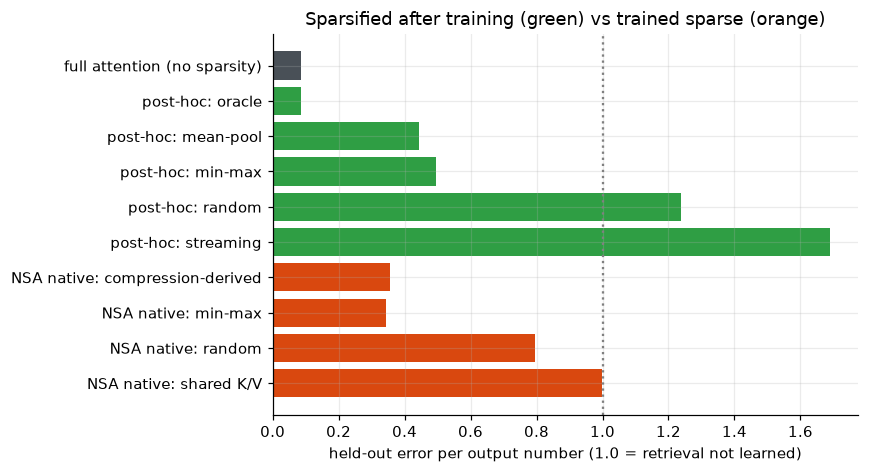

method                                 error
full attention (no sparsity)           0.086
post-hoc: oracle                       0.086
post-hoc: mean-pool                    0.445
post-hoc: min-max                      0.496
post-hoc: random                       1.236
post-hoc: streaming                    1.690
NSA native: compression-derived        0.356
NSA native: min-max                    0.344
NSA native: random                     0.796
NSA native: shared K/V                 0.999


In [11]:
labels = ["full attention (no sparsity)", "post-hoc: oracle", "post-hoc: mean-pool", "post-hoc: min-max", "post-hoc: random", "post-hoc: streaming",
          "NSA native: compression-derived", "NSA native: min-max", "NSA native: random", "NSA native: shared K/V"]
vals = [results["full attention"], post["oracle"], post["mean-pool"], post["min-max"], post["random"], post["streaming"],
        results["NSA (compression-derived)"], results["NSA (min-max heuristic)"], results["NSA (random blocks)"], results["NSA (shared K/V)"]]
cols = [FULL_C] + [WIN_C] * 5 + [SLC_C] * 4
fig, ax = plt.subplots(figsize=(8, 4.4)); ax.barh(labels[::-1], vals[::-1], color=cols[::-1]); ax.axvline(1.0, color="gray", ls=":"); ax.set_xlabel("held-out error per output number (1.0 = retrieval not learned)")
ax.set_title("Sparsified after training (green) vs trained sparse (orange)"); plt.tight_layout(); plt.show()
print(f"{'method':36s} {'error':>7s}")
for l_, v_ in zip(labels, vals): print(f"{l_:36s} {v_:7.3f}")

## How to read the result

The table above is the result; the paragraphs below explain how to interpret it, and we wrote them to hold whichever way individual rows fell.

**The toy's attention is unusually sparse, which flatters post-hoc sparsity.** In our task each scored query needs one far token and a local window. A trained full-attention model therefore puts most of its mass on the target, and an **oracle** selector (which sees that mass) keeps it. Real language-model attention is not that concentrated; the paper's cited figure is that the top 20% of attention weights cover only about 70% of the mass. So a good oracle score here does not contradict the paper's degradation argument; it shows why one must look at the **non-oracle** selectors, the ones a deployed system could afford.

**The comparison that matters is cheap post-hoc selectors versus the natively trained NSA.** Look at the rows for mean-pool, min-max, random and streaming against the NSA rows. If post-hoc cheap selection loses more than native training does, that is evidence for the paper's claim in our setting; if it does not, our toy does not reproduce the claim, and that is also a finding. We make no claim beyond one task, one seed, 128 tokens and a 1-layer model.

**The native variants test the paper's section 6.1.** The paper says a parameter-free heuristic (Quest-style) has low recall and ends with worse loss than NSA's compression-derived scores, and that selection with no information (our random control) should do worst. Compare the three native NSA rows. If the heuristic row is not worse than the compression-derived row here, our toy cannot separate them (we saw in part 2 that on synthetic data their recall was close); the paper's claim was made on a 3B model's loss curve, which we cannot reproduce.

**The shared K/V row tests part 3's isolation claim.** The paper says independent keys and values prevent local patterns from shortcutting the other branches. Our toy has exactly such a local term (the window mean), so it is a fair place to look, but one seed and a small gap would not be evidence either way.

In [12]:
nat, shared = results["NSA (compression-derived)"], results["NSA (shared K/V)"]
best_post_cheap = min(post["mean-pool"], post["min-max"], post["random"], post["streaming"])
print("Verdicts from THIS run (one seed, toy scale):")
print(f"  post-hoc cheap selectors vs native NSA : best cheap post-hoc {best_post_cheap:.3f}  vs  native NSA {nat:.3f}  ->  " + ("native training is better" if nat < best_post_cheap else "post-hoc is as good or better here (claim NOT reproduced on this toy)"))
print(f"  compression-derived vs min-max (native): {nat:.3f} vs {results['NSA (min-max heuristic)']:.3f}  ->  " + ("compression-derived is better" if nat < results['NSA (min-max heuristic)'] else "not better here (claim NOT reproduced on this toy)"))
print(f"  compression-derived vs random (native) : {nat:.3f} vs {results['NSA (random blocks)']:.3f}  ->  " + ("information in the scores matters" if nat < results['NSA (random blocks)'] else "random selection is as good here (the toy does not need selection to be smart)"))
print(f"  independent K/V vs shared K/V          : {nat:.3f} vs {shared:.3f}  ->  " + ("isolation helps" if nat < shared else "no benefit from isolation here (claim NOT reproduced on this toy)"))

Verdicts from THIS run (one seed, toy scale):
  post-hoc cheap selectors vs native NSA : best cheap post-hoc 0.445  vs  native NSA 0.356  ->  native training is better
  compression-derived vs min-max (native): 0.356 vs 0.344  ->  not better here (claim NOT reproduced on this toy)
  compression-derived vs random (native) : 0.356 vs 0.796  ->  information in the scores matters
  independent K/V vs shared K/V          : 0.356 vs 0.999  ->  isolation helps


## The training-efficiency half of the argument

The paper's second argument, that sparsity should help *training* as well as inference, is a statement about kernel speed and cannot be tested on a CPU toy. They report **9.0x forward and 6.0x backward speedup at 64k** against FlashAttention-2 (part 5, Figure 6), and that NSA supports end-to-end training with backward kernels. Methods whose selection is discrete (k-means clustering, hashing) cannot pass gradients through the choice (part 0), and token-granular selection forces scattered reads that defeat FlashAttention-style tiling (part 5). What we reproduced is the *gradient* half: part 2 showed a loss on the compressed branch reaches the compressor that produces the selection scores, so the selector trains without an auxiliary loss.

## Closing thoughts

The design bet is that selection should be learned inside the model's own training loop rather than bolted on, and the paper's evidence for it is a loss-curve comparison on a 3B model (Figure 7) plus downstream benchmarks on 27B (Tables 1-3, Figure 5): average 0.456 vs 0.443 on general benchmarks, 0.469 vs 0.437 on LongBench, and 0.121 vs 0.046 on AIME at 8k tokens after fine-tuning. We reproduced the *mechanism*, a differentiable path to the selection scores, and ran a toy version of the comparison. Open questions we cannot answer here: whether the advantage persists at larger scale on our own runs, how much of NSA's reported gain comes from sparsity as a regulariser (the paper offers this as a possible reason, without isolating it), and whether the three-branch cost of keys and values is the best split. Credit for the design and all reported results belongs to Yuan et al.

**Claims that lack a number or baseline, for you to decide on:** (1) every comparison above is one seed; (2) the paper's auxiliary-loss and clustering alternatives were not reproduced; (3) the toy's attention is far sparser than real attention, so post-hoc selection is favoured; (4) the verdict lines print what this run showed, and a different seed could flip individual rows; (5) all benchmark numbers in the closing paragraph are quoted from the paper.

In [13]:
print(f"{sum(ok for _, ok in CHECKS)}/{len(CHECKS)} checks passed")
for n, ok in CHECKS:
    if not ok: print("FAILED:", n)
assert all(ok for _, ok in CHECKS), "some checks failed"

3/3 checks passed
